In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.signal import windows

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 18})

## test FFT

Text(0.5, 1.0, 'frekvenčna domena')

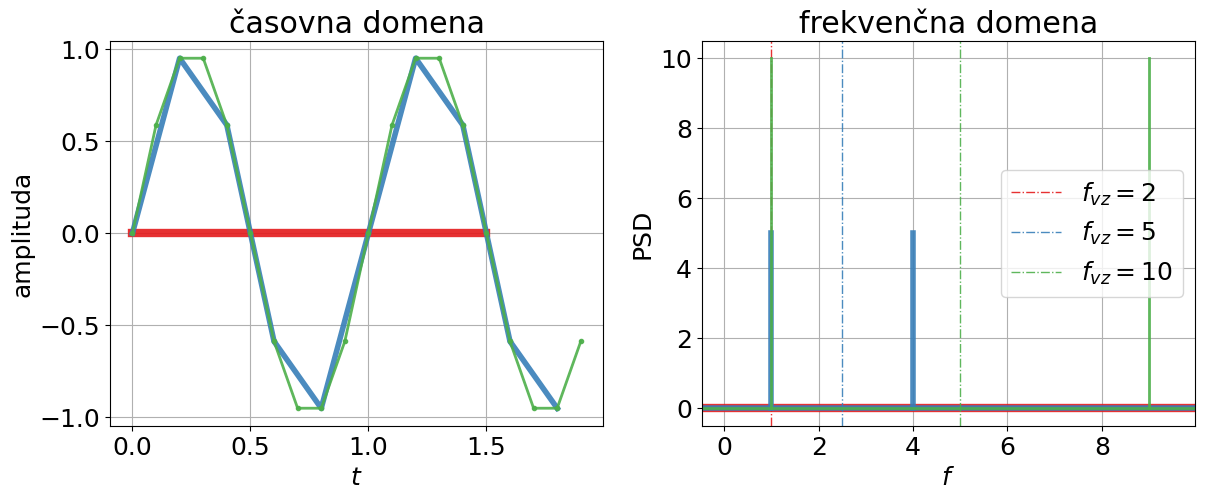

In [2]:
f0 = [2,5,10]
f_vz=5 #frek vzorčenja
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
cmap=plt.get_cmap('Set1')
col=0
linesize=2*len(f0)
for f_vz in f0:
    t0=1/f_vz #perioda
    f_sig=1 #frekvenca signala
    t0_sig=1/f_sig #perioda *2*pi
    t=np.arange(0,2*t0_sig,t0)
    x=np.sin(2 * np.pi*f_sig*t)
    ax1.plot(t,x,'.-', color=cmap(col),alpha=0.9,linewidth=linesize)

    X=np.fft.fft(x)
    n=np.arange(len(X))
    T=len(X)/f_vz
    freq= n/T
    #ax2.plot(freq, np.abs(X), color=cmap(col),alpha=0.9)
    for i in range(len(freq)):
        ax2.plot([freq[i], freq[i]], [0, np.abs(X[i])], color=cmap(col), alpha=0.9,linewidth=linesize)
    ax2.axhline(0, color=cmap(col),alpha=0.9,linewidth=linesize)
    #line1=ax2.axvline(f_sig,color='g')
    line2=ax2.axvline(f_vz/2, color=cmap(col),label=f'$f_{{vz}}=${f_vz}',alpha=0.9,linestyle='dashdot',linewidth=1)
    col+=1
    linesize-=2
ax1.grid()
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.set_title('časovna domena')
plt.legend()
#ax2.legend([line1], ['$f_{sig}$'],loc='best')
ax2.grid()
ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.set_title('frekvenčna domena')
#plt.savefig('slike/testni.pdf',bbox_inches='tight')

## spekter

Text(0.5, 1.0, 'časovna domena')

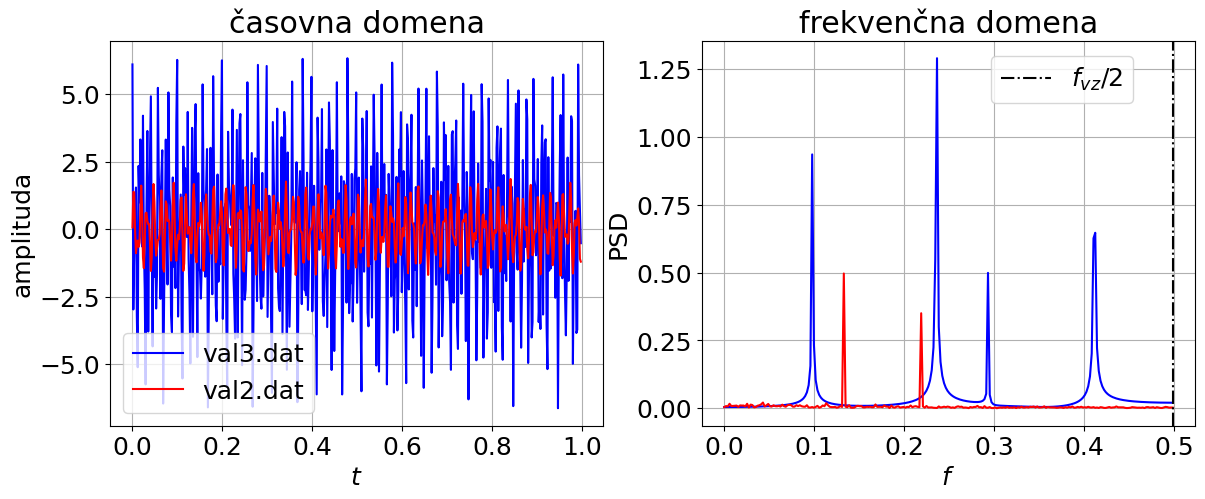

In [3]:
sig2=np.loadtxt('podatki/val2.dat')
sig3=np.loadtxt('podatki/val3.dat')
# sr= 1 #sampling rate, frek. vzorčenja f_vz
# ts=1./sr #sampling interval = t_0
t_max = 1 #cel čas zajema signala
t02=t_max/(len(sig2))
t03=t_max/(len(sig3))
f_vz2=1/t02
f_vz3=1/t03
t2=np.arange(0,t_max,t02)
t3=np.arange(0,t_max,t03)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(t3,sig3,'b-',label='val3.dat')
ax1.plot(t2,sig2,'r-',label='val2.dat')

X2=np.fft.fft(sig2)
n2=np.arange(len(X2))
T2=len(X2)/f_vz2
#freq2= n2/T2
freq2=np.fft.fftfreq(len(sig2))
X3=np.fft.fft(sig3)
n3=np.arange(len(X3))
T3=len(X3)/f_vz3
#freq3= n3/T3
freq3=np.fft.fftfreq(len(sig3))
f_vz2=max(freq3)

window = np.hanning(len(sig2))
sig2_hann = sig2 * window
window = np.hanning(len(sig3))
sig3_hann = sig3 * window

X2_hann=np.fft.fft(sig2_hann)
freq2_hann= np.arange(len(X2_hann))/ len(X2_hann)/f_vz2
X3_hann=np.fft.fft(sig2_hann)
freq3_hann= np.arange(len(X3_hann))/ len(X3_hann)/f_vz3

ax2.plot(freq3[:len(freq3)//2], np.abs(X3[:len(X3)//2])/len(sig3),'b')
ax2.plot(freq2[:len(freq2)//2], np.abs(X2[:len(X2)//2])/len(sig2),'r')
#ax2.plot(freq3[:len(freq3_hann)//2], np.abs(X3_hann[:len(X3_hann)//2]),'b:')
#ax2.plot(freq2[:len(freq2_hann)//2], np.abs(X2_hann[:len(X2_hann)//2]),'r:')

ax2.axvline(f_vz2,color='k',label='$f_{vz}/2$',linestyle='dashdot')
#ax2.axvline(f_vz3/2,color='r',label='$f_{vz}$')#enako
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='k', linestyle='-', label='brez okna'),
                                         plt.Line2D([], [], color='k', linestyle='--', label='Hann')],
                                loc='best', ncol=1)
#ax2.gca().add_artist(legend_line_styles)
ax2.legend(loc='right',bbox_to_anchor=(0.9,0.9))
ax2.grid()
ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.set_title('frekvenčna domena')
ax1.grid()
ax1.legend()
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.set_title('časovna domena')
#plt.savefig('slike/surova_signala.pdf',bbox_inches='tight')

### signal 2

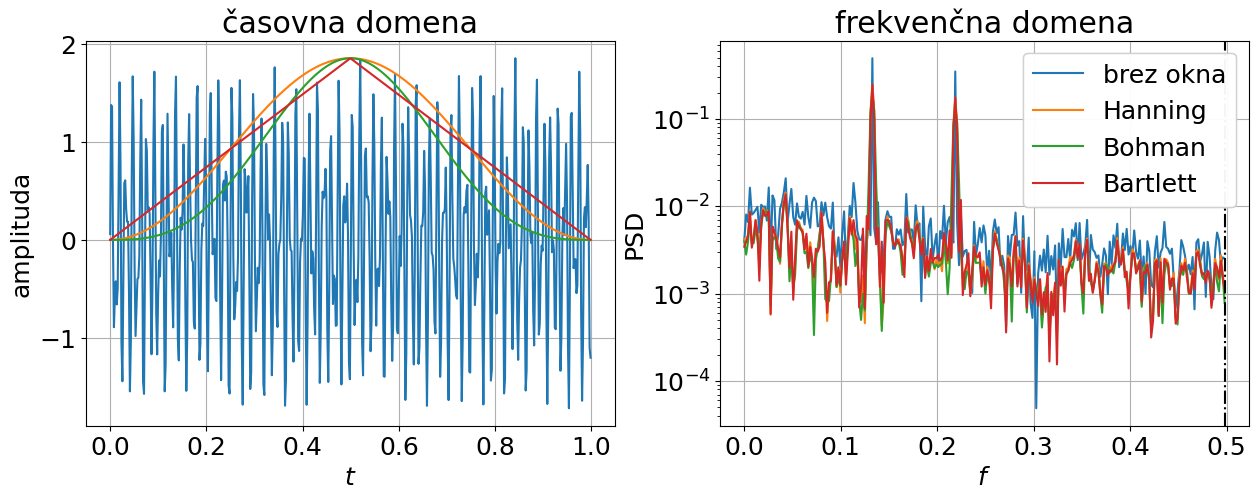

In [4]:
sig2=np.loadtxt('podatki/val2.dat')
sig3=np.loadtxt('podatki/val3.dat')
# sr= 1 #sampling rate, frek. vzorčenja f_vz
# ts=1./sr #sampling interval = t_0
t_max = 1 #cel čas zajema signala
t02=t_max/(len(sig2))
t03=t_max/(len(sig3))
f_vz2=1/t02
f_vz3=1/t03
t2=np.arange(0,t_max,t02)
t3=np.arange(0,t_max,t03)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

X2=np.fft.fft(sig2)
n2=np.arange(len(X2))
T2=len(X2)/f_vz2
freq2= n2/T2
X3=np.fft.fft(sig3)
n3=np.arange(len(X3))
T3=len(X3)/f_vz3
freq3= n3/T3

freq2=np.fft.fftfreq(len(sig2))
f_vz2=max(freq2)

#ax1.plot(t3,sig3,label='val3.dat')
ax1.plot(t2,sig2,label='val2.dat')
#ax2.plot(freq3[:len(freq3)//2], np.abs(X3[:len(X3)//2]))
ax2.plot(freq2[:len(freq2)//2], np.abs(X2[:len(X2)//2])/len(sig2))

window = np.hanning(len(sig2))
sig2_hann = sig2 * window
window = np.hanning(len(sig3))
sig3_hann = sig3 * window
X2_hann=np.fft.fft(sig2_hann)
freq2_hann= np.arange(len(X2_hann))/ len(X2_hann)/f_vz2
X3_hann=np.fft.fft(sig2_hann)
freq3_hann= np.arange(len(X3_hann))/ len(X3_hann)/f_vz3
#ax1.plot(t3,sig3,label='val3.dat')
ax1.plot(t2,window*np.max(sig2))
#ax2.plot(freq3[:len(freq3_hann)//2], np.abs(X3_hann[:len(X3_hann)//2]))
ax2.plot(freq2[:len(freq2_hann)//2], np.abs(X2_hann[:len(X2_hann)//2])/len(sig2))

beta=10
#window = np.kaiser(len(sig2),beta)
window = windows.bohman(len(sig2))
sig2_b = sig2 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig2))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig2))

window = np.bartlett(len(sig2))
sig2_b = sig2 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig2))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig2))

ax2.axvline(f_vz2,color='k',label='$f_{vz}$',linestyle='dashdot')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='C0', label='brez okna'),
                                         plt.Line2D([], [], color='C1', label='Hanning'),
                                         plt.Line2D([], [], color='C2', label='Bohman'),
                                         plt.Line2D([], [], color='C3', label='Bartlett')],
                                loc='best', ncol=1)
plt.gca().add_artist(legend_line_styles)
#ax2.legend(loc='right',bbox_to_anchor=(0.9,0.9))
ax2.grid()
ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.set_title('frekvenčna domena')
ax1.grid()
#ax1.legend()
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.set_title('časovna domena')
plt.yscale('log')
#plt.savefig('slike/okna_sig2.pdf',bbox_inches='tight')

### signal3

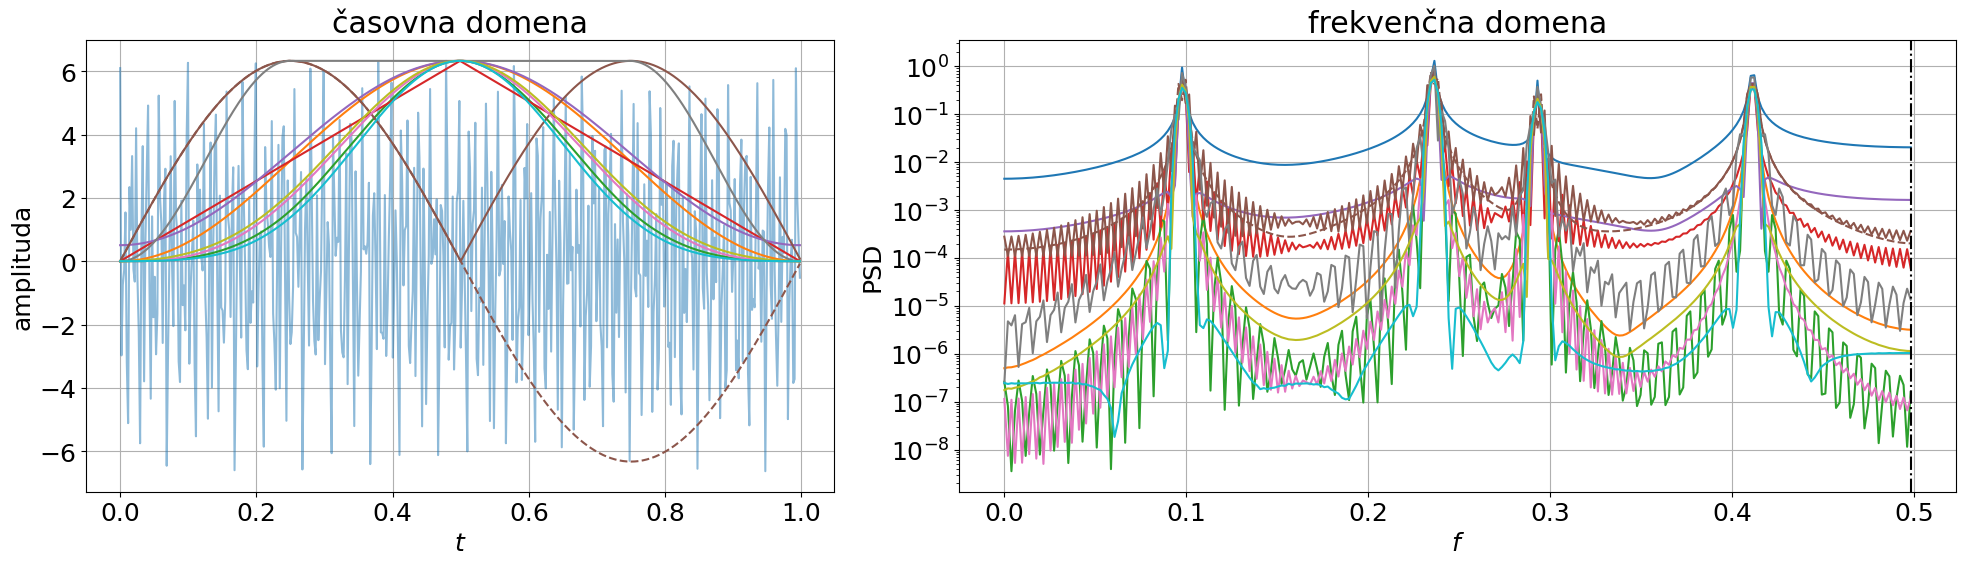

In [5]:
sig2=np.loadtxt('podatki/val2.dat')
sig3=np.loadtxt('podatki/val3.dat')
# sr= 1 #sampling rate, frek. vzorčenja f_vz
# ts=1./sr #sampling interval = t_0
t_max = 1 #cel čas zajema signala
t02=t_max/(len(sig2))
t03=t_max/(len(sig3))
f_vz2=1/t02
f_vz3=1/t03
t2=np.arange(0,t_max,t02)
t3=np.arange(0,t_max,t03)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6),  gridspec_kw={'width_ratios': [1.5, 2]})

X2=np.fft.fft(sig2)
n2=np.arange(len(X2))
T2=len(X2)/f_vz2
freq2= n2/T2
X3=np.fft.fft(sig3)
n3=np.arange(len(X3))
#t3=np.fft.fftfreq(len(sig3))
T3=len(X3)/f_vz3
freq3= n3/T3

freq2=np.fft.fftfreq(len(sig3))
f_vz2=max(freq2)

ax1.plot(t3,sig3,label='val3.dat',alpha=0.5)
#ax1.plot(t2,sig2,label='val2.dat')
ax2.plot(freq2[:len(freq3)//2], np.abs(X3[:len(X3)//2])/len(sig3))
#ax2.plot(freq2[:len(freq2)//2], np.abs(X2[:len(X2)//2]))

window = np.hanning(len(sig2))
sig2_hann = sig3 * window
window = np.hanning(len(sig3))
sig3_hann = sig3 * window
X2_hann=np.fft.fft(sig2_hann)
freq2_hann= np.arange(len(X2_hann))/ len(X2_hann)/f_vz2
X3_hann=np.fft.fft(sig2_hann)
freq3_hann= np.arange(len(X3_hann))/ len(X3_hann)/f_vz3
ax1.plot(t3,window*np.max(sig3))
#ax1.plot(t2,sig2_hann)
ax2.plot(freq2[:len(freq3_hann)//2], np.abs(X3_hann[:len(X3_hann)//2])/len(sig3))
#ax2.plot(freq2[:len(freq2_hann)//2], np.abs(X2_hann[:len(X2_hann)//2]))

beta=3
#window = np.kaiser(len(sig3),beta)
window = windows.parzen(len(sig3))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))

window = np.bartlett(len(sig3))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))

window = np.hamming(len(sig3))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))

window = np.abs(np.sin(t2*2*np.pi))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))
window = (np.sin(t2*2*np.pi))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3),'C5--')
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3),'C5--')

window = windows.bohman(len(sig3))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))

#window = windows.cosine(len(sig3))
window = windows.tukey(len(sig3))
#window = windows.nuttall(len(sig3))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))

window = windows.blackman(len(sig3))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))

window = windows.blackmanharris(len(sig3))
sig2_b = sig3 * window
X2_b=np.fft.fft(sig2_b)
freq2_b= np.arange(len(X2_b))/ len(X2_b)/f_vz2
ax1.plot(t2,window*np.max(sig3))
ax2.plot(freq2[:len(freq2_b)//2], np.abs(X2_b[:len(X2_b)//2])/len(sig3))

fig.subplots_adjust(top=3, right=3)
ax2.axvline(f_vz2,color='k',label='$f_{vz}$',linestyle='dashdot')
legend_line_styles = ax2.legend(handles=[plt.Line2D([], [], color='C0', label='brez okna'),
                                         plt.Line2D([], [], color='C1', label='Hann'),
                                         plt.Line2D([], [], color='C2', label='Parzen'),
                                         plt.Line2D([], [], color='C3', label='Bartlett'),
                                         plt.Line2D([], [], color='C4', label='Hamming'),
                                         plt.Line2D([], [], color='C5', label='abs(sin)'),
                                         plt.Line2D([], [], color='C5', label='sinus',linestyle='--'),
                                         plt.Line2D([], [], color='C6', label='Bohman'),
                                         plt.Line2D([], [], color='C7', label='Tukey'),
                                         plt.Line2D([], [], color='C8', label='Blackmann'),
                                         plt.Line2D([], [], color='C9', label='Blackmann_Harris')],
                                loc='center left', bbox_to_anchor=(1, 0.5),ncol=1)
fig.gca().add_artist(legend_line_styles)
#ax2.legend(loc='right',bbox_to_anchor=(0.9,0.9))
ax2.grid()
ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.set_title('frekvenčna domena')
ax1.grid()
#ax1.legend()
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.set_title('časovna domena')
plt.yscale('log')
#plt.tight_layout()
#plt.savefig('slike/okna_sig3.pdf',bbox_inches='tight', bbox_extra_artists=(legend_line_styles,))#dela OK
#plt.show()
#plt.plot(0,0)
# legend_line_styles_ = ax2.legend(handles=[plt.Line2D([], [], color='C0', label='brez okna'),
#                                          plt.Line2D([], [], color='C1', label='Hann'),
#                                          plt.Line2D([], [], color='C2', label='Parzen'),
#                                          plt.Line2D([], [], color='C3', label='Bartlett'),
#                                          plt.Line2D([], [], color='C4', label='Hamming'),
#                                          plt.Line2D([], [], color='C5', label='abs(sin)'),
#                                          plt.Line2D([], [], color='C5', label='sinus',linestyle='--'),
#                                          plt.Line2D([], [], color='C6', label='Bohman'),
#                                          plt.Line2D([], [], color='C7', label='Tukey'),
#                                          plt.Line2D([], [], color='C8', label='Blackmann'),
#                                          plt.Line2D([], [], color='C9', label='Blackmann_Harris')],
#                                 loc='best',bbox_to_anchor=(1,1))
# plt.gca().add_artist(legend_line_styles_)
plt.tight_layout()
#plt.savefig('slike/okna_sig3.pdf',bbox_inches='tight', bbox_extra_artists=(legend_line_styles,))#dela OK
plt.show()

# izpust

Text(0.5, 1.0, 'časovna domena')

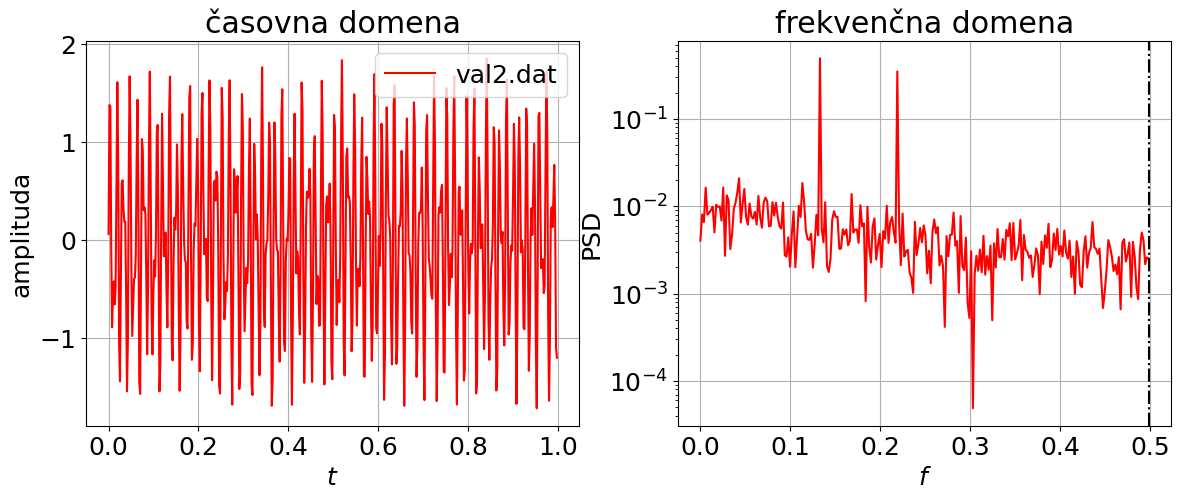

In [6]:
sig2=np.loadtxt('podatki/val2.dat')
t_max = 1 #cel čas zajema signala
t02=t_max/(len(sig2))
t2=np.arange(0,t_max,t02)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(t2,sig2,'r-',label='val2.dat')

X2=np.fft.fft(sig2)
n2=np.arange(len(X2))
T2=len(X2)/f_vz2
freq2= n2/T2
f2=np.fft.fftfreq(len(sig2))
f_vz2=max(f2)

#ax2.plot(freq2[:len(freq2)//2], np.abs(X2[:len(X2)//2])/len(sig2),'r')
ax2.plot(f2[:len(f2)//2], np.abs(X2[:len(X2)//2])/len(sig2), 'r')
ax2.axvline(f_vz2,color='k',label='$f_{vz}$',linestyle='dashdot')

ax2.grid()
ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.set_title('frekvenčna domena')
ax2.set_yscale('log')
ax1.grid()
ax1.legend()
ax1.set_xlabel('$t$')
ax1.set_ylabel('amplituda')
ax1.set_title('časovna domena')

In [45]:
def vzorčenje(N,val):
    sig2=np.loadtxt('podatki/val'+val+'.dat')
    sig2 = sig2[:N:]
    #fvz=1/step
    #fvz = len(sig2)/512
    #print(len(sig2))

    X2=np.fft.fft(sig2)
    f2=np.fft.fftfreq(len(sig2))

    ax1.plot(f2[:len(f2)//2], np.abs(X2[:len(X2)//2])/len(sig2), label=str(N))
def izpuščanje(N,val):
    sig2=np.loadtxt('podatki/val'+val+'.dat')
    sig2 = sig2[::N]
    #fvz=1/step
    #fvz = len(sig2)/512
    #print(len(sig2))

    X2=np.fft.fft(sig2)
    f2=np.fft.fftfreq(len(sig2))

    ax2.plot(f2[:len(f2)//2], np.abs(X2[:len(X2)//2])/len(sig2), label=str(N)+f'$, (N={len(sig2)})$')
plt.rcParams.update({'font.size': 12})

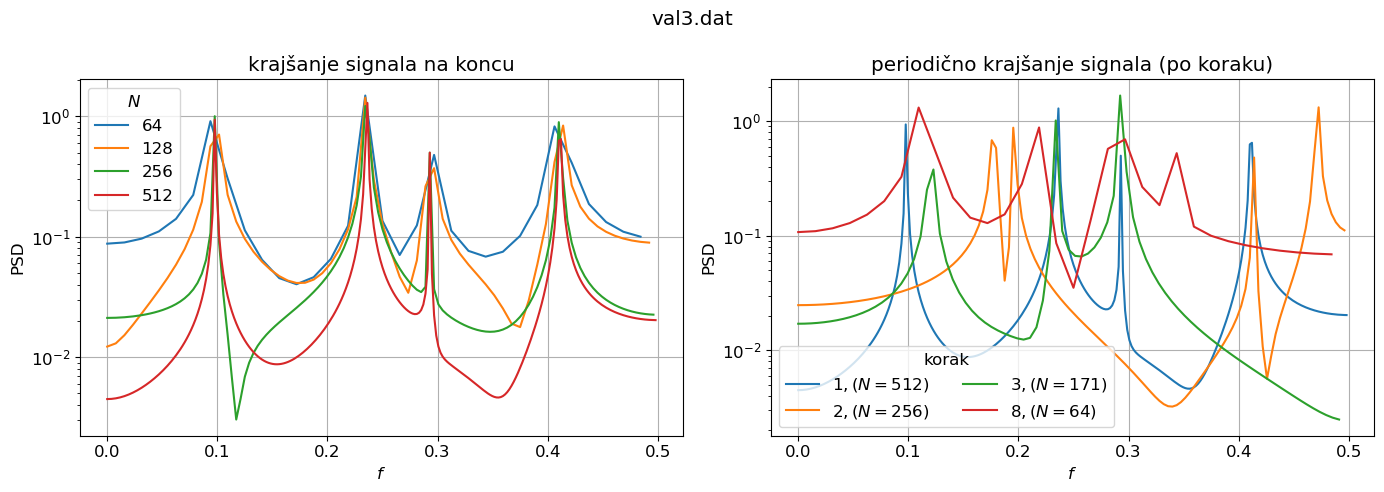

In [54]:
val = '3'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
#ax1.plot(t2,sig3,'r-',label='val3.dat')

vzorčenje(64,val)
vzorčenje(128,val)
vzorčenje(256,val)
vzorčenje(512,val)
ax1.legend(title='$N$')

izpuščanje(1,val)
izpuščanje(2,val)
izpuščanje(4,val)
izpuščanje(8,val)
ax2.legend(title='korak',ncol=2,loc='lower left')

ax2.grid()
ax2.set_xlabel('$f$')
ax2.set_ylabel('PSD')
ax2.set_title('periodično krajšanje signala (po koraku)')
ax2.set_yscale('log')

ax1.grid()
ax1.set_xlabel('$f$')
ax1.set_ylabel('PSD')
ax1.set_title('krajšanje signala na koncu')
ax1.set_yscale('log')

plt.suptitle('val'+val+'.dat')
plt.tight_layout()
#plt.savefig('slike/izpust_sig'+val+'.pdf')